# 03 · Tüm gökyüzü taraması

Kaynak listesi kullanmadan, gökyüzünün her noktasında (HEALPix nside = 64, ~0,9° piksel) aynı likelihood fit edilir.
En yüksek TS'li nokta (“hotspot”) kuzey ve güney yarıküre için ayrı raporlanır.
Haritanın üretimi birkaç dakika sürdüğü için `scripts/run_skymap.py` ile önceden hesaplanır.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

import astropy.units as u
from astropy.coordinates import SkyCoord

from vcube.data import PROCESSED_DIR
from vcube.skymap import hottest, mollweide_xy, plot_mollweide
from vcube.sources import CANDIDATES
from vcube.trials import sigma_from_p

sky = dict(np.load(PROCESSED_DIR / "skymap_nside64.npz"))
nside = int(sky["nside"])

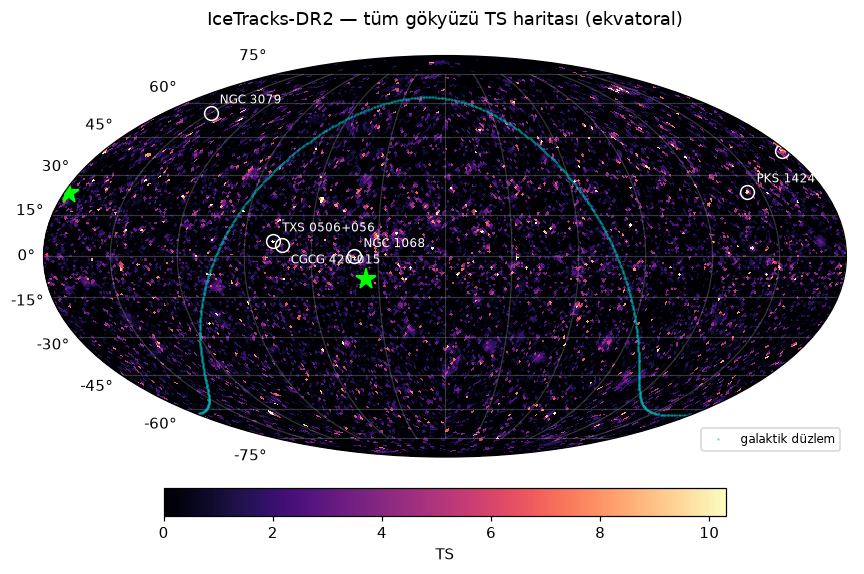

In [2]:
ts = np.nan_to_num(sky["ts"])
ax = plot_mollweide(ts, nside, vmax=np.percentile(ts, 99.9))
ax.set_title("IceTracks-DR2 — tüm gökyüzü TS haritası (ekvatoral)", pad=20)

gal = SkyCoord(l=np.linspace(0, 360, 721) * u.deg, b=0 * u.deg, frame="galactic").icrs
x, y = mollweide_xy(gal.ra.rad, gal.dec.rad)
order = np.argsort(x)
ax.plot(x[order], y[order], "c.", ms=1, alpha=0.6, label="galaktik düzlem")
for name, ra, dec in CANDIDATES[:6]:
    x, y = mollweide_xy(np.radians(ra), np.radians(dec))
    ax.plot(x, y, "o", mfc="none", mec="w", ms=9)
    offset = (6, -12) if name == "CGCG 420-015" else (6, 6)
    ax.annotate(name, (x, y), xytext=offset, textcoords="offset points", color="w", fontsize=8)
hots = {h: hottest(sky, r) for h, r in (("kuzey", (-5, 85)), ("güney", (-85, -5)))}
for h, s in hots.items():
    x, y = mollweide_xy(s["ra"], s["dec"])
    ax.plot(x, y, "*", c="lime", ms=14)
ax.legend(loc="lower right", fontsize=8)
plt.gcf().savefig(FIG / "03_tum_gok.png", bbox_inches="tight")

In [3]:
rows = []
scr_path = PROCESSED_DIR / f"scrambled_hottest_nside32.npz"
scr = dict(np.load(scr_path)) if scr_path.exists() else None
MIN_SCRAMBLES = 10
if scr is not None and len(scr["north"]) < MIN_SCRAMBLES:
    print(f"Yalnızca {len(scr['north'])} karıştırılmış gökyüzü var; post-trial p için en az {MIN_SCRAMBLES} gerekir "
          "(scripts/run_skymap.py --nside 32 --scrambles N). Şimdilik sadece lokal sonuçlar gösteriliyor.")
    scr = None
for h, s in hots.items():
    row = {"yarıküre": h, "RA [°]": round(np.degrees(s["ra"]), 2), "Dec [°]": round(np.degrees(s["dec"]), 2),
           "TS": round(s["ts"], 2), "n_s": round(s["ns"], 1), "γ": round(s["gamma"], 2)}
    if scr is not None:
        key = "north" if h == "kuzey" else "south"
        n_above = np.sum(scr[key] >= s["ts"])
        row["post-trial p"] = f"{max(n_above, 1) / len(scr[key]):.2f}" + (" (üst sınır)" if n_above == 0 else "")
        row["karıştırılmış gök"] = len(scr[key])
    rows.append(row)
pd.DataFrame(rows)

Yalnızca 2 karıştırılmış gökyüzü var; post-trial p için en az 10 gerekir (scripts/run_skymap.py --nside 32 --scrambles N). Şimdilik sadece lokal sonuçlar gösteriliyor.


,yarıküre,RA [°],Dec [°],TS,n_s,γ
0,kuzey,177.89,23.32,20.67,18.7,2.04
1,güney,35.86,-8.39,14.68,18.4,3.03


**Yorum:** Tüm gökyüzü taramasında binlerce bağımsız nokta denendiği için (“look-elsewhere” etkisi), en sıcak noktanın lokal anlamlılığı
yüksek görünse de post-trial anlamlılığı ancak karıştırılmış gökyüzlerinin en sıcak noktalarıyla karşılaştırılarak değerlendirilebilir.
IceCube'un kendi taramalarında da kuzey hotspot'u NGC 1068 yakınında çıkmaktadır.

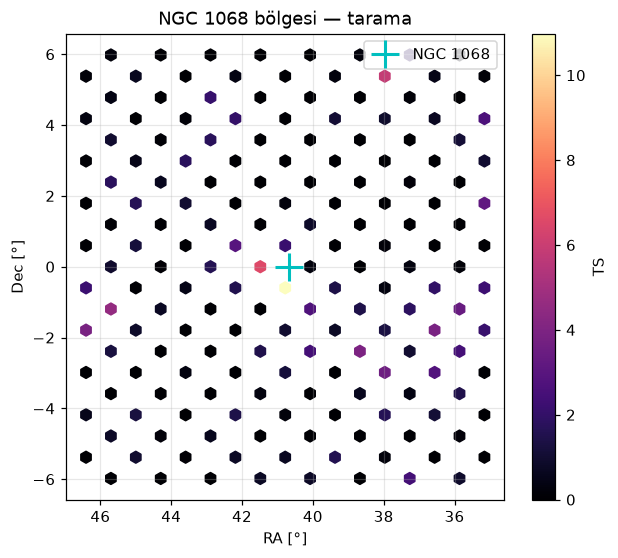

In [4]:
from vcube.sources import source
ra0, dec0 = source("NGC 1068")
near = (np.abs(sky["dec"] - dec0) < np.radians(6)) & (np.abs(np.mod(sky["ra"] - ra0 + np.pi, 2 * np.pi) - np.pi) < np.radians(6))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(np.degrees(sky["ra"][near]), np.degrees(sky["dec"][near]), c=ts[near], s=60, marker="h", cmap="magma")
plt.colorbar(sc, label="TS")
ax.plot(np.degrees(ra0), np.degrees(dec0), "c+", ms=18, mew=2, label="NGC 1068")
ax.set(xlabel="RA [°]", ylabel="Dec [°]", title="NGC 1068 bölgesi — tarama", aspect="equal")
ax.invert_xaxis()
ax.legend()
fig.savefig(FIG / "03_ngc1068_bolge.png", bbox_inches="tight")